# RCA Activity 1 — Multiple Linear Regression
## Project: House Value Prediction using the California Housing Dataset

**Course:** Regression and Classification Algorithms  
**Unit:** Unit I – Regression Foundations & Linear Regression  
**Objective:** Fit and interpret single-feature and multiple linear regression models, verify a small-sample calculation manually, evaluate test performance, and examine residuals and multicollinearity.

**Dataset:** California Housing dataset supplied by Scikit-learn. The target `MedHouseVal` is expressed in units of $100,000.

> Run the notebook from top to bottom. The dataset loader may need an internet connection the first time it downloads the dataset. Use the actual outputs generated by your run in your submitted report; do not invent metric values.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load and understand the dataset

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset shape:", df.shape)
display(df.head())
print("\\nDataset information:")
df.info()
display(df.describe().T)

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


### Feature and target description

The eight numerical input features are:
- `MedInc`: median income
- `HouseAge`: median house age
- `AveRooms`: average rooms
- `AveBedrms`: average bedrooms
- `Population`: population
- `AveOccup`: average occupancy
- `Latitude`: geographic latitude
- `Longitude`: geographic longitude

Target: `MedHouseVal`, median house value in units of $100,000.

## 3. Data quality checks and cleaning

In [3]:
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows and rows with missing values, if any.
before = len(df)
df = df.drop_duplicates().dropna().copy()
print(f"Rows before cleaning: {before}; rows after cleaning: {len(df)}")
print("Cleaned dataset shape:", df.shape)

Missing values by column:


,missing_values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Duplicate rows: 0
Rows before cleaning: 20640; rows after cleaning: 20640
Cleaned dataset shape: (20640, 9)


## 4. Exploratory data analysis and visualisation

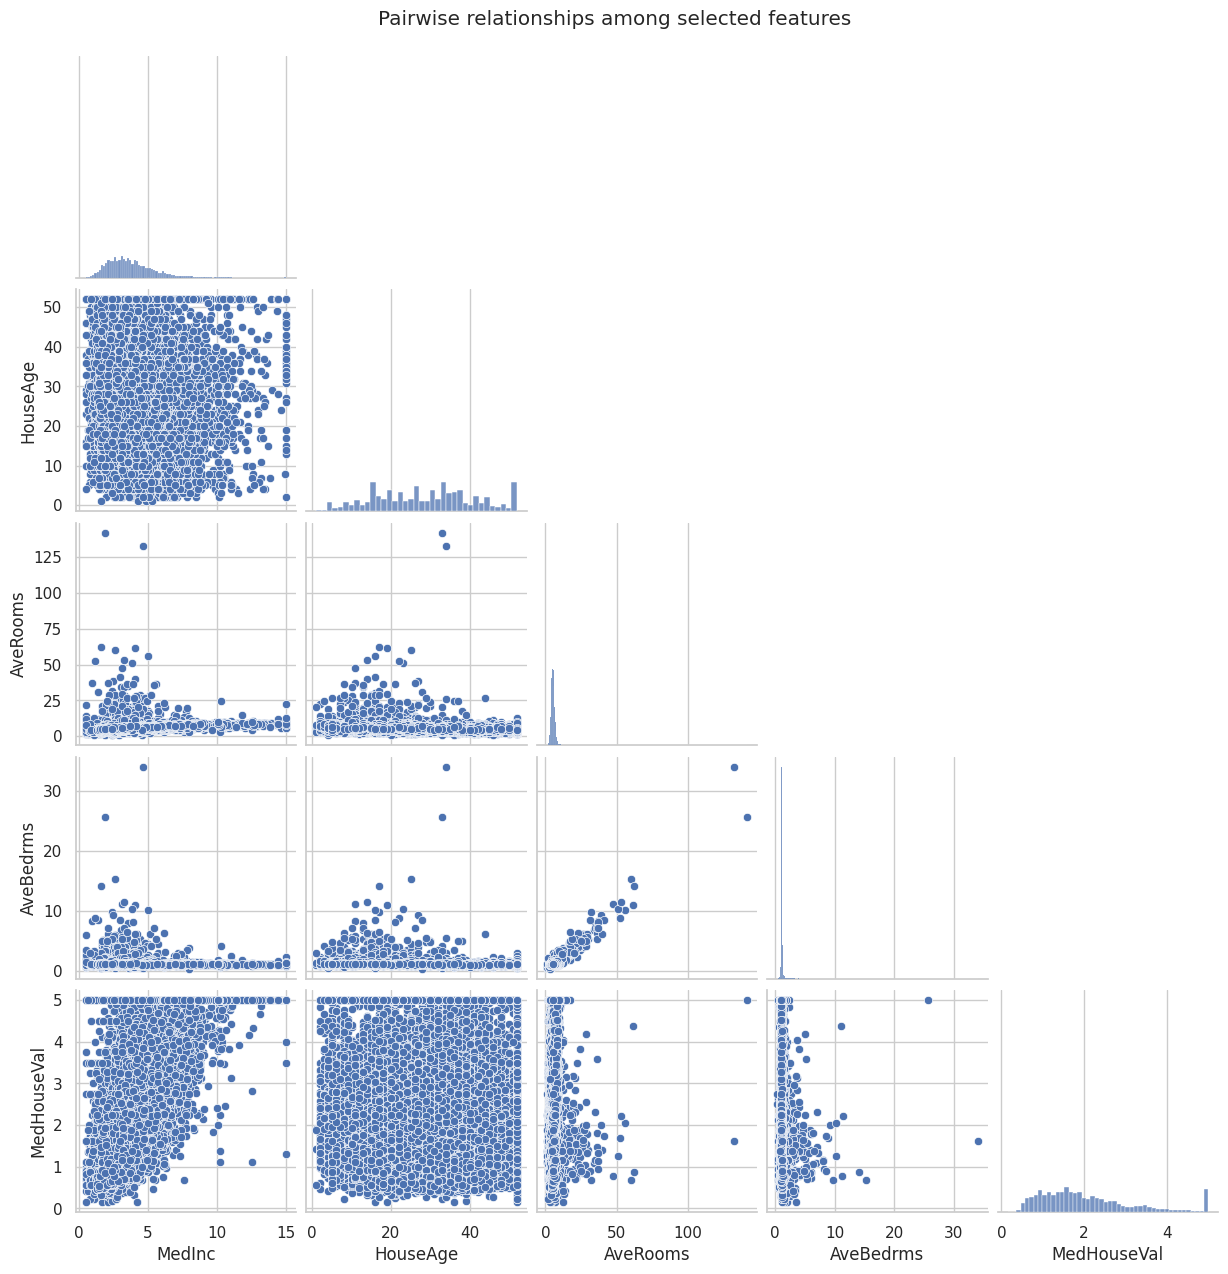

In [4]:
features_for_plot = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "MedHouseVal"]
sns.pairplot(df[features_for_plot], corner=True, diag_kind="hist")
plt.suptitle("Pairwise relationships among selected features", y=1.02)
plt.show()

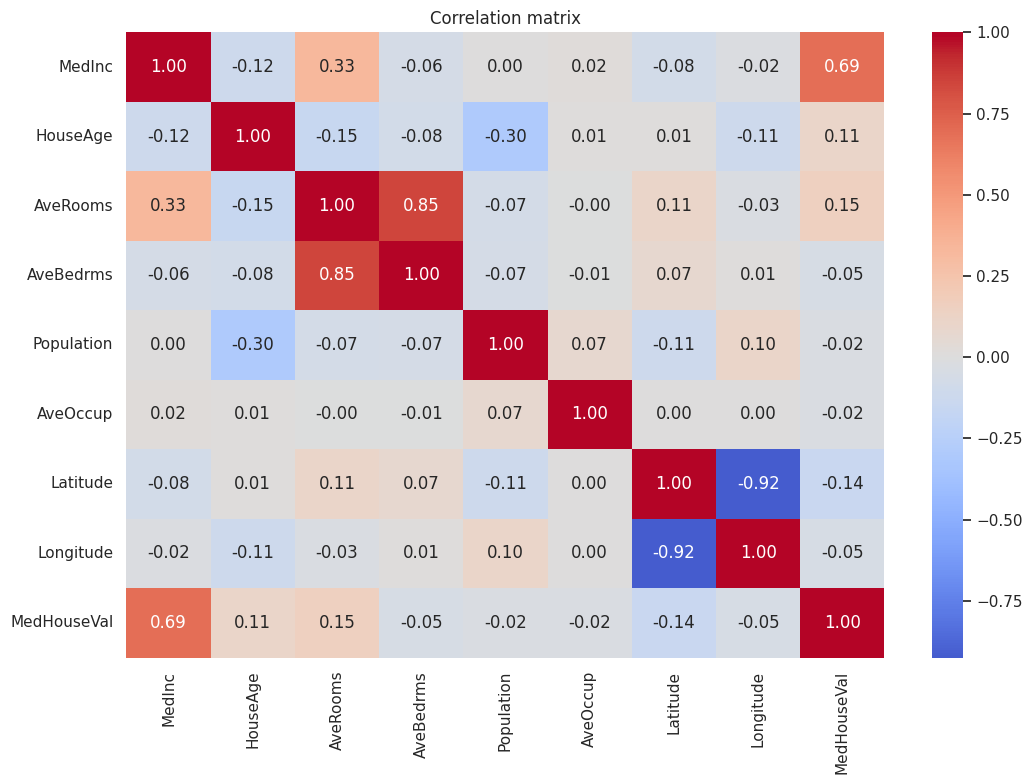

,correlation_with_target
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [5]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

target_corr = df.corr(numeric_only=True)["MedHouseVal"].drop("MedHouseVal").sort_values(
    key=lambda s: s.abs(), ascending=False
)
display(target_corr.to_frame("correlation_with_target"))

**Interpretation prompt:** Identify the feature with the strongest absolute correlation with `MedHouseVal`. Also inspect correlations among input features for possible multicollinearity. Correlation describes association; it does not prove causation.

## 5. Manual least-squares calculation using two features

Use six observations and two predictors:
- \(X_1\) = `MedInc`
- \(X_2\) = `HouseAge`
- \(y\) = `MedHouseVal`

The model is \(y = b_0 + b_1X_1 + b_2X_2\). The design matrix contains a leading column of ones. We solve \((X^TX)b=X^Ty\).

In [6]:
sample = df[["MedInc", "HouseAge", "MedHouseVal"]].head(6).copy()
display(sample)

X_manual = np.column_stack([
    np.ones(len(sample)),
    sample[["MedInc", "HouseAge"]].to_numpy()
])
y_manual = sample["MedHouseVal"].to_numpy()

XTX = X_manual.T @ X_manual
XTy = X_manual.T @ y_manual

print("Design matrix X:")
print(X_manual)
print("\\nTarget vector y:")
print(y_manual)
print("\\nX transpose X:")
print(XTX)
print("\\nX transpose y:")
print(XTy)

manual_coef = np.linalg.solve(XTX, XTy)
print("\\n[b0, b1, b2] from normal equations:")
print(manual_coef)

,MedInc,HouseAge,MedHouseVal
0,8.3252,41.0,4.526
1,8.3014,21.0,3.585
2,7.2574,52.0,3.521
3,5.6431,52.0,3.413
4,3.8462,52.0,3.422
5,4.0368,52.0,2.697


Design matrix X:
[[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]
 [ 1.      4.0368 52.    ]]
\nTarget vector y:
[4.526 3.585 3.521 3.413 3.422 2.697]
\nX transpose X:
[[6.00000000e+00 3.74101000e+01 2.70000000e+02]
 [3.74101000e+01 2.53825638e+02 1.59640460e+03]
 [2.70000000e+02 1.59640460e+03 1.29380000e+04]]
\nX transpose y:
[ 21.164     136.3025259 939.607    ]
\n[b0, b1, b2] from normal equations:
[1.25635916 0.26774578 0.01336833]


In [7]:
# Predict the first observation and calculate its residual.
manual_prediction = X_manual[0] @ manual_coef
manual_residual = y_manual[0] - manual_prediction
print("First observation actual value:", y_manual[0])
print("First observation predicted value:", manual_prediction)
print("Residual (actual - predicted):", manual_residual)

First observation actual value: 4.526
First observation predicted value: 4.033497777673302
Residual (actual - predicted): 0.4925022223266975


## 6. Verify the manual calculation with Scikit-learn

In [8]:
manual_library_model = LinearRegression()
manual_library_model.fit(sample[["MedInc", "HouseAge"]], sample["MedHouseVal"])

print("Manual intercept:", manual_coef[0])
print("Library intercept:", manual_library_model.intercept_)
print("Manual slopes:", manual_coef[1:])
print("Library slopes:", manual_library_model.coef_)
print("Maximum absolute coefficient difference:",
      np.max(np.abs(manual_coef - np.r_[manual_library_model.intercept_,
                                       manual_library_model.coef_])))

Manual intercept: 1.2563591611656546
Library intercept: 1.2563591611656566
Manual slopes: [0.26774578 0.01336833]
Library slopes: [0.26774578 0.01336833]
Maximum absolute coefficient difference: 1.9984014443252818e-15


## 7. Train/test split

In [9]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of input features:", X_train.shape[1])

Training rows: 16512
Testing rows: 4128
Number of input features: 8


## 8. Single-feature baseline model

In [10]:
# Select the predictor with the strongest absolute training-set correlation with the target.
train_correlations = X_train.apply(lambda col: col.corr(y_train)).abs()
best_feature = train_correlations.idxmax()
print("Selected single feature:", best_feature)

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)
single_pred = single_model.predict(X_test[[best_feature]])

print("Single-feature intercept:", single_model.intercept_)
print("Single-feature coefficient:", single_model.coef_[0])

Selected single feature: MedInc
Single-feature intercept: 0.4445972916907879
Single-feature coefficient: 0.4193384939381271


## 9. Multiple-feature regression model

In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)

print("Multiple-model intercept:", multiple_model.intercept_)
coefficients = pd.Series(multiple_model.coef_, index=X.columns, name="coefficient")
display(coefficients.to_frame())

Multiple-model intercept: -37.02327770606405


,coefficient
MedInc,0.448675
HouseAge,0.009724
AveRooms,-0.123323
AveBedrms,0.783145
Population,-0.000002
AveOccup,-0.003526
Latitude,-0.419792
Longitude,-0.433708


### Fitted equation

The fitted model has the form:

`MedHouseVal = intercept + b1*MedInc + b2*HouseAge + ... + b8*Longitude`

Each coefficient describes the predicted change in the target for a one-unit increase in that feature, **holding the other included features constant**. The intercept is the model prediction when all features equal zero; that combination may not be meaningful in this dataset. Raw coefficient magnitudes should not be compared directly because the features use different units.

## 10. Evaluate and compare models on the test set

In [12]:
def regression_metrics(actual, predicted, p):
    n = len(actual)
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse,
            "R2": r2, "Adjusted R2": adjusted_r2}

comparison = pd.DataFrame(
    [
        regression_metrics(y_test, single_pred, 1),
        regression_metrics(y_test, multiple_pred, X_test.shape[1])
    ],
    index=["Single-feature model", "Multiple-feature model"]
)
display(comparison.round(4))

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature model,0.6299,0.7091,0.8421,0.4589,0.4587
Multiple-feature model,0.5332,0.5559,0.7456,0.5758,0.5750


**Metric interpretation**
- **MAE:** average absolute prediction error, in target units.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, in target units.
- **R²:** comparison with predicting the test-set mean; test R² can be negative.
- **Adjusted R²:** adjusts R² for the number of predictors.

Use the table to decide whether the extra predictors improve test performance enough to justify the added complexity.

## 11. Actual and predicted values

In [13]:
prediction_table = pd.DataFrame({
    "Actual MedHouseVal": y_test.to_numpy(),
    "Predicted MedHouseVal": multiple_pred,
    "Residual": y_test.to_numpy() - multiple_pred
}, index=y_test.index)
display(prediction_table.head(10))

,Actual MedHouseVal,Predicted MedHouseVal,Residual
20046,0.47700,0.719123,-0.242123
3024,0.45800,1.764017,-1.306017
15663,5.00001,2.709659,2.290351
20484,2.18600,2.838926,-0.652926
9814,2.78000,2.604657,0.175343
13311,1.58700,2.011754,-0.424754
7113,1.98200,2.645500,-0.663500
7668,1.57500,2.168755,-0.593755
18246,3.40000,2.740746,0.659254
5723,4.46600,3.915615,0.550385


## 12. Residual analysis

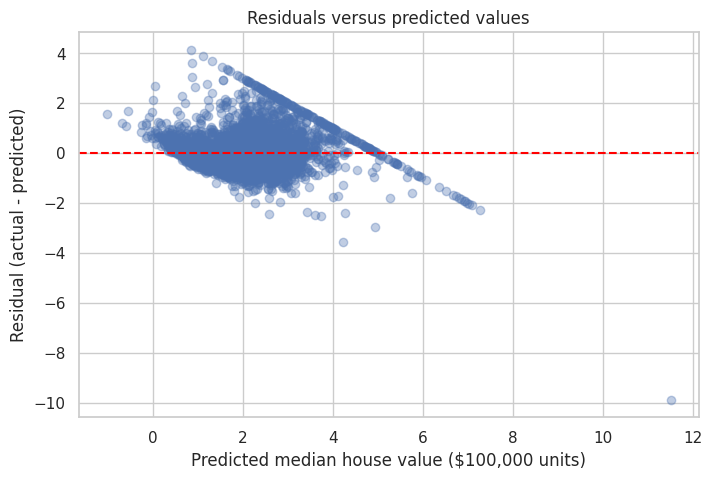

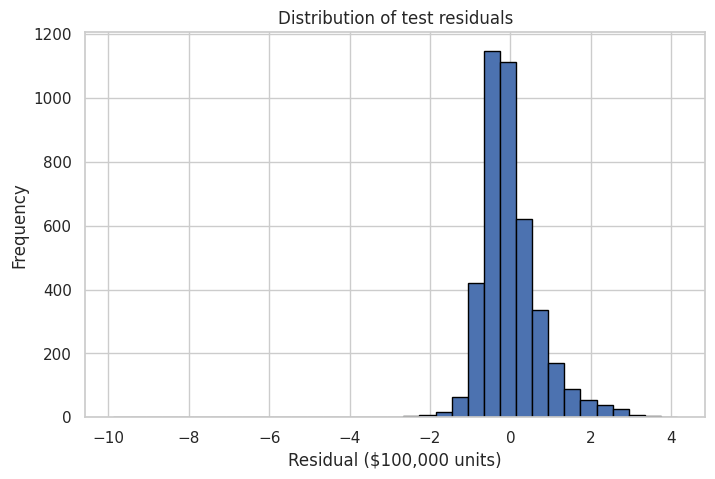

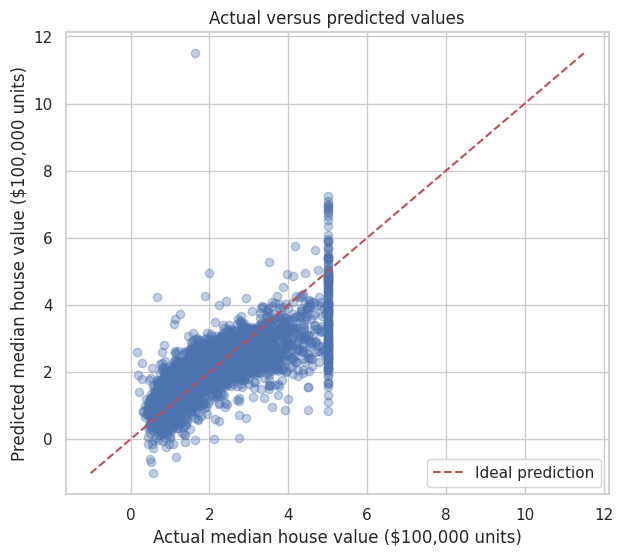

In [14]:
residuals = y_test.to_numpy() - multiple_pred

plt.figure(figsize=(8, 5))
plt.scatter(multiple_pred, residuals, alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted median house value ($100,000 units)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals versus predicted values")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=35, edgecolor="black")
plt.xlabel("Residual ($100,000 units)")
plt.ylabel("Frequency")
plt.title("Distribution of test residuals")
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(y_test, multiple_pred, alpha=0.35)
low = min(y_test.min(), multiple_pred.min())
high = max(y_test.max(), multiple_pred.max())
plt.plot([low, high], [low, high], "r--", label="Ideal prediction")
plt.xlabel("Actual median house value ($100,000 units)")
plt.ylabel("Predicted median house value ($100,000 units)")
plt.title("Actual versus predicted values")
plt.legend()
plt.show()

**Residual interpretation prompts:** A random cloud around zero is consistent with linearity and roughly constant variance. A curve or funnel shape may indicate non-linearity or non-constant variance. A roughly symmetric histogram is supportive of approximate normality, but visual checks are not proof. Independence depends on how observations were collected; geographic observations may have spatial dependence.

## 13. Multicollinearity check using VIF

In [15]:
# VIF can be computationally intensive; calculate it on the training predictors.
# Standardising is not required for VIF, but does not change the VIF values.
X_vif = sm.add_constant(X_train.astype(float))
vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})
display(vif_table.sort_values("VIF", ascending=False))

,Feature,VIF
7,Latitude,9.206134
8,Longitude,8.875984
3,AveRooms,7.917240
4,AveBedrms,6.609200
1,MedInc,2.539815
2,HouseAge,1.237337
5,Population,1.134824
6,AveOccup,1.009733
0,const,1.000000


A high VIF indicates that a predictor can be explained by other predictors. A VIF above 5 is commonly used as a warning threshold, not an absolute rule. Consider whether highly redundant variables should be removed or combined, then refit and compare test performance.

## 14. Standardised coefficients (for relative scale comparison)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

standardised_coefficients = pd.Series(
    scaled_model.coef_, index=X.columns, name="standardised_coefficient"
).sort_values(key=lambda s: s.abs(), ascending=False)
display(standardised_coefficients.to_frame())

,standardised_coefficient
Latitude,-0.896929
Longitude,-0.869842
MedInc,0.854383
AveBedrms,0.339259
AveRooms,-0.294410
HouseAge,0.122546
AveOccup,-0.040829
Population,-0.002308


Standardised coefficients put predictors on a common scale and can help compare their conditional associations in this fitted linear model. They do not establish causation.

## 15. Predict a new example

In [17]:
# Use the training-set median for each feature to create an in-range example.
new_house = pd.DataFrame([X_train.median()], columns=X.columns)
new_prediction = multiple_model.predict(new_house)[0]

# Check whether each new feature value is within its training range.
range_check = pd.DataFrame({
    "new_value": new_house.iloc[0],
    "training_min": X_train.min(),
    "training_max": X_train.max()
})
range_check["within_training_range"] = (
    (range_check["new_value"] >= range_check["training_min"]) &
    (range_check["new_value"] <= range_check["training_max"])
)

display(range_check)
print(f"Predicted median house value: {new_prediction:.4f} units of $100,000")
print(f"Approximate value in dollars: ${new_prediction * 100000:,.2f}")

,new_value,training_min,training_max,within_training_range
MedInc,3.545800,0.499900,15.000100,True
HouseAge,29.000000,1.000000,52.000000,True
AveRooms,5.235874,0.888889,141.909091,True
AveBedrms,1.049286,0.333333,25.636364,True
Population,1167.000000,3.000000,35682.000000,True
AveOccup,2.817240,0.692308,1243.333333,True
Latitude,34.260000,32.550000,41.950000,True
Longitude,-118.510000,-124.350000,-114.310000,True


Predicted median house value: 2.0300 units of $100,000
Approximate value in dollars: $203,002.36


## 16. Decision log

Complete this table using the results from your own notebook run.

| Decision | Your evidence and reasoning |
|---|---|
| Why were these predictors selected? | |
| How were missing values or duplicates handled? | |
| Which feature had the strongest target correlation? | |
| Did multiple regression improve test metrics? | |
| Which features showed high VIF? | |
| Which regression assumptions looked doubtful? | |
| What limitation should users know? | |

## 17. Conclusion

Write a conclusion based on your actual outputs. Include:
1. Dataset size and selected predictors.
2. The fitted model's intercept and coefficients.
3. Test-set comparison of the single-feature and multiple-feature models.
4. MAE, RMSE, R² and adjusted R².
5. What the residual plots and VIF suggest.
6. The new example prediction and its units.
7. One limitation: this linear model may miss non-linear relationships, location effects, or other factors; it should not be used to claim causation.

**Do not report results until you have run the notebook and checked the outputs.**

## References
- California Housing dataset information: https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html
- Scikit-learn dataset documentation: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset
- Scikit-learn LinearRegression documentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
